# **Mice Protein Expression: classification of the 8 classes**

> **Question: do the profiles of the 77 proteins predict the eight experimental classes in mice not seen during training?**

The audit (`01_data_audit.ipynb`) showed that the 15 measurements of an animal are much closer to each other than to those of other animals. Here the **animal** is therefore the unit of splitting and of evaluation, and two data representations are compared:

- the original measurements (1080 rows, 15 per animal), with one prediction per animal obtained by averaging the probabilities of its measurements;
- the per-animal mean of each protein (72 rows).

## **1. Imports**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## **2. Download data**

In [2]:
df_full = fetch_ucirepo(id=342).data.original

mouse_parts = df_full["MouseID"].str.split("_", expand=True)
df = df_full.assign(
    animal_id=mouse_parts[0],
    measurement=pd.to_numeric(mouse_parts[1], errors="raise"),
)

protein_cols = [c for c in df.columns if c.endswith("_N")]
meta_cols = ["Genotype", "Treatment", "Behavior", "class"]

## **3. Datasets**

### **3.1 Measurement matrix: all protein expression measurements**

In [3]:
df_protein = df[protein_cols]

df_protein

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
0,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,...,0.188852,0.122652,NaN,0.106305,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652
1,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,...,0.200404,0.116682,NaN,0.106592,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610
2,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,...,0.193685,0.118508,NaN,0.108303,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427
3,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,...,0.192112,0.132781,NaN,0.103184,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563
4,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,...,0.205604,0.129954,NaN,0.104784,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1075,0.254860,0.463591,0.254860,2.092082,2.600035,0.211736,0.171262,2.483740,0.207317,1.057971,...,0.275547,0.190483,NaN,0.115806,0.183324,0.374088,0.318782,0.204660,0.328327,1.364823
1076,0.272198,0.474163,0.251638,2.161390,2.801492,0.251274,0.182496,2.512737,0.216339,1.081150,...,0.283207,0.190463,NaN,0.113614,0.175674,0.375259,0.325639,0.200415,0.293435,1.364478
1077,0.228700,0.395179,0.234118,1.733184,2.220852,0.220665,0.161435,1.989723,0.185164,0.884342,...,0.290843,0.216682,NaN,0.118948,0.158296,0.422121,0.321306,0.229193,0.355213,1.430825
1078,0.221242,0.412894,0.243974,1.876347,2.384088,0.208897,0.173623,2.086028,0.192044,0.922595,...,0.306701,0.222263,NaN,0.125295,0.196296,0.397676,0.335936,0.251317,0.365353,1.404031


In [4]:
y_protein = df["class"]

y_protein

0       c-CS-m
1       c-CS-m
2       c-CS-m
3       c-CS-m
4       c-CS-m
         ...  
1075    t-SC-s
1076    t-SC-s
1077    t-SC-s
1078    t-SC-s
1079    t-SC-s
Name: class, Length: 1080, dtype: str

### **3.2 Per-animal mean matrix**

In [5]:
df_animal = df.groupby("animal_id")[protein_cols].mean()

df_animal

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
animal_id,,,,,,,,,,,,,,,,,,,,,
18899,0.428381,0.617834,0.299208,2.053351,3.461564,0.281945,0.191150,2.541373,0.210844,1.556977,...,0.236160,0.192990,0.179952,0.120311,NaN,0.424551,0.207383,NaN,0.264955,1.328343
293,0.268072,0.532736,0.293274,2.278292,3.466264,0.255595,0.193701,3.825613,0.240396,1.203226,...,0.204713,0.139175,0.121962,0.134576,0.110451,0.494021,0.426291,0.170461,0.297441,1.257729
294,0.318000,0.486584,0.315980,2.479140,3.838981,0.261231,0.204978,5.130094,0.223610,1.365092,...,0.272471,NaN,NaN,0.133939,0.137972,0.483603,NaN,0.236137,0.230726,1.058736
309,0.421063,0.576510,0.356447,2.278252,4.354744,0.219549,0.182195,1.922373,0.196064,1.422933,...,0.192871,0.151524,NaN,0.101042,0.115433,0.423088,0.136374,0.169300,0.169590,1.674160
311,0.600591,0.678479,0.334548,2.277561,4.234706,0.227820,0.184262,1.931669,0.176511,1.874307,...,0.188092,0.166315,0.168952,0.105205,NaN,0.426774,0.141512,0.201386,0.200284,1.193285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50810E,0.508742,0.748007,0.318928,2.299097,3.791904,0.209596,0.163295,2.570700,0.212496,1.386207,...,0.231358,0.163582,0.134391,0.107420,0.133887,0.499405,0.183951,0.172079,0.211742,1.704720
50810F,0.439384,0.560736,0.331974,2.224129,3.968663,0.278213,0.206829,3.747682,0.258409,1.532130,...,0.194244,NaN,NaN,0.108895,0.114522,0.366727,NaN,NaN,NaN,1.455950
J1291,0.241612,0.421927,0.291766,2.145327,2.954803,0.270469,0.186234,3.249092,0.246158,1.030867,...,0.225712,0.163488,NaN,0.113939,NaN,0.334016,0.293926,0.160057,0.250398,1.355835


In [6]:
metadata_per_animal = df.groupby("animal_id")[meta_cols].first()

y_animal = metadata_per_animal.loc[df_animal.index, "class"]

y_animal

animal_id
18899     t-CS-s
293       t-SC-m
294       c-SC-m
309       c-CS-m
311       c-CS-m
           ...  
50810E    t-CS-s
50810F    c-CS-s
J1291     t-SC-s
J2292     c-SC-s
J3295     t-SC-s
Name: class, Length: 72, dtype: str

## **4. Split the data**

80/20 split **over animals**, not over rows. The animal IDs are drawn once, stratified by the animal's class, and both matrices are cut from them:

- `df_animal` (means): the rows of those IDs.
- `df_protein` (measurements): the 15 rows of each of those animals, which go to the same side together.

The same 15 animals are therefore in the test set of both representations, and no animal is in both full_train and test.

In [7]:
# NumPy array: train_test_split cannot index the Arrow-backed string Index pandas uses with pyarrow
train_animals, test_animals = train_test_split(
    df_animal.index.to_numpy(),
    test_size=0.2,
    stratify=y_animal,
    random_state=42,
)

In [8]:
# Average per animal: one row = one animal
X_animal_full_train = df_animal.loc[train_animals]
X_animal_test = df_animal.loc[test_animals]
y_animal_full_train = y_animal.loc[train_animals]
y_animal_test = y_animal.loc[test_animals]

In [9]:
is_test_row = df["animal_id"].isin(test_animals)

# 15 protein measurements per animal
X_protein_full_train = df_protein[~is_test_row]
X_protein_test = df_protein[is_test_row]
y_protein_full_train = y_protein[~is_test_row]
y_protein_test = y_protein[is_test_row]

In [10]:
# Checks: same test animals in both matrices and no animal on both sides
assert set(df.loc[is_test_row, "animal_id"]) == set(test_animals)
assert set(df.loc[~is_test_row, "animal_id"]) == set(train_animals)
assert set(train_animals).isdisjoint(test_animals)

print(f"Animals: {len(train_animals)} full_train, {len(test_animals)} test")
print(f"Measurements: {len(X_protein_full_train)} full_train, {len(X_protein_test)} test")

pd.DataFrame({
    "full_train (animals)": y_animal_full_train.value_counts(),
    "test (animals)": y_animal_test.value_counts(),
}).sort_index()

Animals: 57 full_train, 15 test
Measurements: 855 full_train, 225 test


,full_train (animals),test (animals)
class,,
c-CS-m,8,2
c-CS-s,7,2
c-SC-m,8,2
c-SC-s,7,2
t-CS-m,7,2
t-CS-s,6,1
t-SC-m,7,2
t-SC-s,7,2


## **5. Cross-validation folds**

Cross-validation folds for the grid search, defined **over the 57 full_train animals** (5 folds stratified by class, fixed seed) and translated into row positions of each matrix:

- `cv_animal`: positions in `X_animal_full_train` (one row per animal).
- `cv_protein`: positions in `X_protein_full_train` (the 15 measurements of each animal together).

Both matrices use the same validation animals in each fold, and no animal is in training and validation at the same time. The test set is not used.

In [11]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Folds defined over the 57 full_train animals
animal_folds = [
    (y_animal_full_train.index[train], y_animal_full_train.index[val])
    for train, val in inner_cv.split(X_animal_full_train, y_animal_full_train)
]

# The same folds, as positions, for each matrix
full_train_animal_ids = df.loc[~is_test_row, "animal_id"]

cv_animal = [
    (np.flatnonzero(X_animal_full_train.index.isin(train)),
     np.flatnonzero(X_animal_full_train.index.isin(val)))
    for train, val in animal_folds
]
cv_protein = [
    (np.flatnonzero(full_train_animal_ids.isin(train)),
     np.flatnonzero(full_train_animal_ids.isin(val)))
    for train, val in animal_folds
]

In [12]:
class_order = sorted(y_animal_full_train.unique())

# Checks: same validation animals in both matrices and no animal on both sides
for (train_a, val_a), (train_p, val_p) in zip(cv_animal, cv_protein):
    val_animals = set(X_animal_full_train.index[val_a])
    assert val_animals == set(full_train_animal_ids.iloc[val_p])
    assert set(X_animal_full_train.index[train_a]) == set(full_train_animal_ids.iloc[train_p])
    assert val_animals.isdisjoint(full_train_animal_ids.iloc[train_p])

pd.DataFrame(
    [
        {"fold": fold,
         "train animals": len(train_a), "validation animals": len(val_a),
         "train measurements": len(train_p), "validation measurements": len(val_p),
         **y_animal_full_train.iloc[val_a].value_counts().reindex(class_order, fill_value=0)}
        for fold, ((train_a, val_a), (train_p, val_p)) in enumerate(zip(cv_animal, cv_protein), start=1)
    ]
).set_index("fold")

,train animals,validation animals,train measurements,validation measurements,c-CS-m,c-CS-s,c-SC-m,c-SC-s,t-CS-m,t-CS-s,t-SC-m,t-SC-s
fold,,,,,,,,,,,,
1,45,12,675,180,2,1,2,1,2,2,1,1
2,45,12,675,180,2,1,2,1,2,1,1,2
3,46,11,690,165,2,1,2,1,1,1,1,2
4,46,11,690,165,1,2,1,2,1,1,2,1
5,46,11,690,165,1,2,1,2,1,1,2,1


## **6. Models and hyperparameter grids**

Three pipelines. In all of them the imputation is fitted only on the training part of each fold; in the logistic regression, so is the standardization.

| Model | Fixed parameters | Grid (means) | Grid (measurements) |
|---|---|---|---|
| Dummy | `strategy="most_frequent"` | imputation | imputation |
| Logistic regression | `max_iter=5000` | imputation, `C` ∈ {0.001, 0.01, 0.1, 1, 10, 100, 1000} | same as means |
| Random forest | `n_estimators=500`, `random_state=42` | imputation, `min_samples_leaf` ∈ {1, 2, 3}, `max_features` ∈ {sqrt, 0.3, 0.6} | imputation, `min_samples_leaf` ∈ {1, 5, 15, 30, 60}, `max_features` ∈ {sqrt, 0.3, 0.6} |

Imputation: `strategy` ∈ {median, mean}.

`min_samples_leaf` changes scale between matrices: in the means, a leaf of 3 samples is 3 animals; in the measurements, each animal takes 15 rows, so a leaf of 15 can be a single animal. The upper limits of `C` (1000) and of `min_samples_leaf` for the measurements (60) were extended after a first run in which the chosen values (100 and 30) were at the edge of the grid; the choices did not change.

In [13]:
pipelines = {
    "Dummy": Pipeline([
        ("imputer", SimpleImputer()),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic regression": Pipeline([
        ("imputer", SimpleImputer()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000)),
    ]),
    "Random forest": Pipeline([
        ("imputer", SimpleImputer()),
        ("model", RandomForestClassifier(n_estimators=500, random_state=42)),
    ]),
}

In [14]:
imputer_grid = {"imputer__strategy": ["median", "mean"]}
lr_grid = {**imputer_grid, "model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

param_grids = {
    # Means: each row is an animal
    "animal": {
        "Dummy": imputer_grid,
        "Logistic regression": lr_grid,
        "Random forest": {
            **imputer_grid,
            "model__min_samples_leaf": [1, 2, 3],
            "model__max_features": ["sqrt", 0.3, 0.6],
        },
    },
    # Measurements: each animal takes 15 rows, so leaves are larger
    "protein": {
        "Dummy": imputer_grid,
        "Logistic regression": lr_grid,
        "Random forest": {
            **imputer_grid,
            "model__min_samples_leaf": [1, 5, 15, 30, 60],
            "model__max_features": ["sqrt", 0.3, 0.6],
        },
    },
}

In [15]:
# Check: every combination is accepted by its pipeline
for grids in param_grids.values():
    for name, grid in grids.items():
        for params in ParameterGrid(grid):
            clone(pipelines[name]).set_params(**params)

pd.DataFrame(
    {matrix: {name: len(ParameterGrid(grid)) for name, grid in grids.items()}
     for matrix, grids in param_grids.items()}
).rename_axis("combinations")

,animal,protein
combinations,,
Dummy,2,2
Logistic regression,14,14
Random forest,18,30


## **7. Grid search**

One `GridSearchCV` per model and matrix, on full_train, with the animal-level folds of section 5. The test set is not used here.

**Animal-level metric for both matrices.** The scorer groups the validation rows by animal, averages the probabilities and predicts the class with the highest mean probability. In the means matrix each row is already an animal, so this equals the usual metric. In the measurements matrix the 15 rows of each animal become a single prediction. Both matrices are therefore selected and compared on the same unit: the animal.

**Selection:** `refit="f1_macro"`. The combination with the best mean F1 macro over the 5 folds is refitted on the whole full_train. Accuracy is reported alongside. Values are mean ± standard deviation over the 5 folds (sklearn's, with `ddof=0`).

In [16]:
def predict_by_animal(estimator, X, y, row_to_animal):
    """One prediction per animal: mean of the probabilities of its rows, class with the highest mean.

    In the means matrix each row is already an animal and the aggregation changes nothing.
    """
    animal = pd.Series(row_to_animal(X.index), index=X.index)
    proba = pd.DataFrame(estimator.predict_proba(X), index=X.index, columns=estimator.classes_)
    y_pred = proba.groupby(animal).mean().idxmax(axis=1)
    y_true = y.groupby(animal).first().loc[y_pred.index]
    return pd.DataFrame({"y_true": y_true, "y_pred": y_pred})


def animal_metrics(by_animal):
    return {
        "accuracy": accuracy_score(by_animal["y_true"], by_animal["y_pred"]),
        "f1_macro": f1_score(by_animal["y_true"], by_animal["y_pred"], labels=class_order, average="macro", zero_division=0),
    }


def animal_level_scorer(row_to_animal):
    """GridSearchCV scorer that evaluates one prediction per animal."""
    def scorer(estimator, X, y):
        return animal_metrics(predict_by_animal(estimator, X, y, row_to_animal))
    return scorer


def animal_id_from_animal_matrix(index):
    return np.asarray(index)


def animal_id_from_protein_matrix(index):
    return df.loc[index, "animal_id"].to_numpy()

In [17]:
datasets = {
    "animal": (X_animal_full_train, y_animal_full_train, cv_animal, animal_id_from_animal_matrix),
    "protein": (X_protein_full_train, y_protein_full_train, cv_protein, animal_id_from_protein_matrix),
}

searches = {}
for matrix, (X, y, cv, row_to_animal) in datasets.items():
    for name, pipeline in pipelines.items():
        searches[(matrix, name)] = GridSearchCV(
            pipeline,
            param_grids[matrix][name],
            scoring=animal_level_scorer(row_to_animal),
            refit="f1_macro",
            cv=cv,
            n_jobs=-1,
        ).fit(X, y)

### **7.1 Best combination per model (used in the refit)**

In [18]:
def mean_std(results, metric, i):
    return f"{results[f'mean_test_{metric}'][i]:.3f} ± {results[f'std_test_{metric}'][i]:.3f}"


def model_params(params):
    return ", ".join(f"{k.removeprefix('model__')}={v}" for k, v in params.items() if k.startswith("model__")) or "—"


pd.DataFrame(
    [
        {"matrix": matrix, "model": name,
         "imputation": search.best_params_["imputer__strategy"],
         "hyperparameters": model_params(search.best_params_),
         "F1 macro": mean_std(search.cv_results_, "f1_macro", search.best_index_),
         "accuracy": mean_std(search.cv_results_, "accuracy", search.best_index_)}
        for (matrix, name), search in searches.items()
    ]
).set_index(["matrix", "model"])

imputation                        hyperparameters  \
matrix  model                                                                   
animal  Dummy                   median                                      —   
        Logistic regression       mean                                  C=100   
        Random forest           median   max_features=0.6, min_samples_leaf=2   
protein Dummy                   median                                      —   
        Logistic regression     median                                  C=0.1   
        Random forest             mean  max_features=0.3, min_samples_leaf=30   

                                  F1 macro       accuracy  
matrix  model                                              
animal  Dummy                0.030 ± 0.008  0.139 ± 0.040  
        Logistic regression  0.503 ± 0.107  0.541 ± 0.110  
        Random forest        0.458 ± 0.152  0.476 ± 0.153  
protein Dummy                0.030 ± 0.008  0.139 ± 0.040  
        Logistic regression  0.569 ± 0.072  0.648 ± 0.055  
        Random forest        0.501 ± 0.067  0.559 ± 0.069

### **7.2 Results by matrix and imputation**

Best combination of each model within each of the four conditions (matrix × imputation), from the cross-validation on full_train. When median and mean tie, the refit keeps the first combination of the grid.

In [19]:
cv_rows = pd.DataFrame(
    [
        {"matrix": matrix, "imputation": params["imputer__strategy"], "model": name,
         "hyperparameters": model_params(params),
         "f1_mean": search.cv_results_["mean_test_f1_macro"][i],
         "F1 macro": mean_std(search.cv_results_, "f1_macro", i),
         "accuracy": mean_std(search.cv_results_, "accuracy", i)}
        for (matrix, name), search in searches.items()
        for i, params in enumerate(search.cv_results_["params"])
    ]
)

# Best combination of each model within each matrix × imputation
best_by_imputation = cv_rows.loc[cv_rows.groupby(["matrix", "imputation", "model"])["f1_mean"].idxmax()]

for (matrix, strategy), table in best_by_imputation.groupby(["matrix", "imputation"]):
    print(f"Matrix: {matrix} | imputation: {strategy}")
    display(table.set_index("model")[["hyperparameters", "F1 macro", "accuracy"]])

Matrix: animal | imputation: mean


,hyperparameters,F1 macro,accuracy
model,,,
Dummy,—,0.030 ± 0.008,0.139 ± 0.040
Logistic regression,C=100,0.503 ± 0.107,0.541 ± 0.110
Random forest,"max_features=0.6, min_samples_leaf=2",0.441 ± 0.130,0.458 ± 0.124


Matrix: animal | imputation: median


,hyperparameters,F1 macro,accuracy
model,,,
Dummy,—,0.030 ± 0.008,0.139 ± 0.040
Logistic regression,C=100,0.495 ± 0.114,0.541 ± 0.110
Random forest,"max_features=0.6, min_samples_leaf=2",0.458 ± 0.152,0.476 ± 0.153


Matrix: protein | imputation: mean


,hyperparameters,F1 macro,accuracy
model,,,
Dummy,—,0.030 ± 0.008,0.139 ± 0.040
Logistic regression,C=0.1,0.569 ± 0.072,0.648 ± 0.055
Random forest,"max_features=0.3, min_samples_leaf=30",0.501 ± 0.067,0.559 ± 0.069


Matrix: protein | imputation: median


,hyperparameters,F1 macro,accuracy
model,,,
Dummy,—,0.030 ± 0.008,0.139 ± 0.040
Logistic regression,C=0.1,0.569 ± 0.072,0.648 ± 0.055
Random forest,"max_features=0.6, min_samples_leaf=30",0.489 ± 0.105,0.564 ± 0.099


## **8. Test evaluation**

Each model refitted on full_train with its chosen hyperparameters (`best_estimator_`) is evaluated **once** on the 15 test animals, which took part neither in the grid search nor in the refit. No hyperparameter is adjusted based on the test.

The metric is per animal for both matrices, with the same aggregation as the grid search. With 15 animals, each animal is worth about 6.7 percentage points of accuracy, and t-CS-s has a single test animal: the test is a noisy estimate without a standard deviation, and the cross-validation alongside gives the reference for variability. A difference of 1 or 2 animals between models is not enough to rank them.

The deployed model (`train.py`) is the one with the best cross-validated F1 macro: logistic regression on the measurements, median imputation, `C=0.1`.

In [20]:
test_sets = {
    "animal": (X_animal_test, y_animal_test, animal_id_from_animal_matrix),
    "protein": (X_protein_test, y_protein_test, animal_id_from_protein_matrix),
}

# Each model refitted on full_train predicts the 15 test animals, one prediction per animal
test_predictions = {
    (matrix, name): predict_by_animal(search.best_estimator_, *test_sets[matrix])
    for (matrix, name), search in searches.items()
}

for predictions in test_predictions.values():
    assert set(predictions.index) == set(test_animals)

In [21]:
test_results = pd.DataFrame(
    [
        {"matrix": matrix, "model": name,
         "imputation": search.best_params_["imputer__strategy"],
         "hyperparameters": model_params(search.best_params_),
         "F1 macro (CV)": mean_std(search.cv_results_, "f1_macro", search.best_index_),
         "accuracy (CV)": mean_std(search.cv_results_, "accuracy", search.best_index_),
         "F1 macro (test)": round(metrics["f1_macro"], 3),
         "accuracy (test)": round(metrics["accuracy"], 3),
         "correct animals": f"{(predictions['y_true'] == predictions['y_pred']).sum()} of {len(predictions)}"}
        for (matrix, name), search in searches.items()
        for predictions in [test_predictions[(matrix, name)]]
        for metrics in [animal_metrics(predictions)]
    ]
).set_index(["matrix", "model"])
test_results

imputation                        hyperparameters  \
matrix  model                                                                   
animal  Dummy                   median                                      —   
        Logistic regression       mean                                  C=100   
        Random forest           median   max_features=0.6, min_samples_leaf=2   
protein Dummy                   median                                      —   
        Logistic regression     median                                  C=0.1   
        Random forest             mean  max_features=0.3, min_samples_leaf=30   

                             F1 macro (CV)  accuracy (CV)  F1 macro (test)  \
matrix  model                                                                
animal  Dummy                0.030 ± 0.008  0.139 ± 0.040            0.029   
        Logistic regression  0.503 ± 0.107  0.541 ± 0.110            0.792   
        Random forest        0.458 ± 0.152  0.476 ± 0.153            0.875   
protein Dummy                0.030 ± 0.008  0.139 ± 0.040            0.029   
        Logistic regression  0.569 ± 0.072  0.648 ± 0.055            0.792   
        Random forest        0.501 ± 0.067  0.559 ± 0.069            0.933   

                             accuracy (test) correct animals  
matrix  model                                                 
animal  Dummy                          0.133         2 of 15  
        Logistic regression            0.867        13 of 15  
        Random forest                  0.867        13 of 15  
protein Dummy                          0.133         2 of 15  
        Logistic regression            0.867        13 of 15  
        Random forest                  0.933        14 of 15

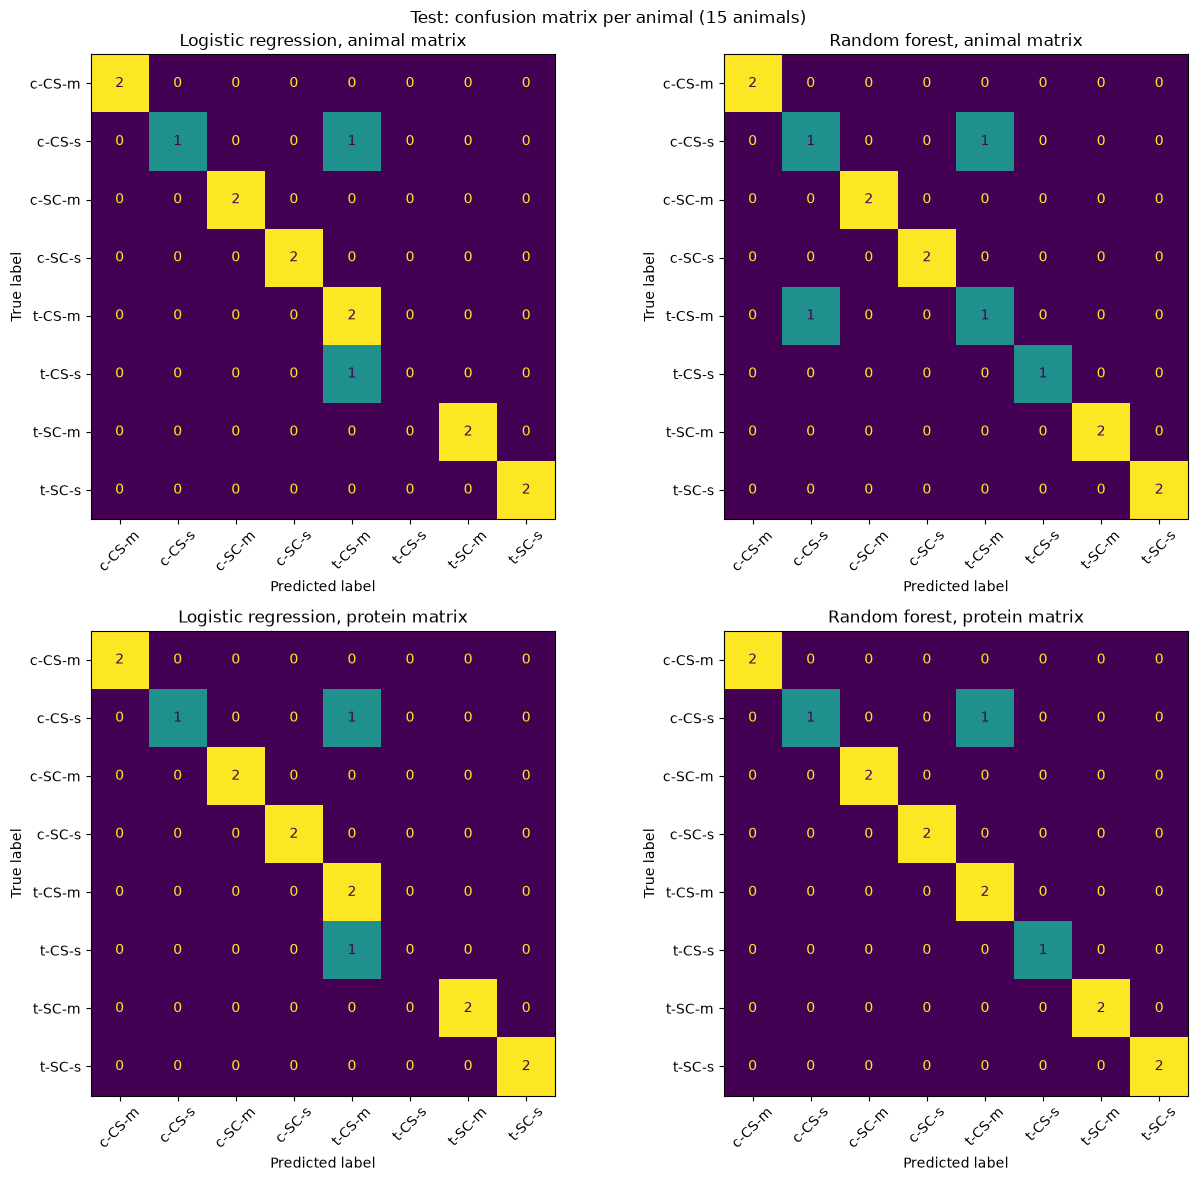

In [22]:
panels = [(matrix, name) for matrix in ["animal", "protein"] for name in ["Logistic regression", "Random forest"]]

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, (matrix, name) in zip(axes.flat, panels):
    predictions = test_predictions[(matrix, name)]
    ConfusionMatrixDisplay.from_predictions(
        predictions["y_true"], predictions["y_pred"], labels=class_order,
        ax=ax, colorbar=False, xticks_rotation=45,
    )
    ax.set_title(f"{name}, {matrix} matrix")
fig.suptitle("Test: confusion matrix per animal (15 animals)")
plt.tight_layout()
plt.show()